# Lab 7 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab07.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import torch
import lab07

data = lab07.load_data('../data/machine_events.npz')
results = lab07.run_experiment(data)
results

{'mean_pool': {'accuracy': 0.471, 'loss': 0.7018},
 'encoder_nopos': {'accuracy': 0.49, 'loss': 0.7003},
 'encoder_pos': {'accuracy': 0.97, 'loss': 0.1335}}

## Plot 1 — What the positional encoding actually is

`positional_encoding(16, 32)` is a fixed 16 x 32 table. Look at it before you plot it.

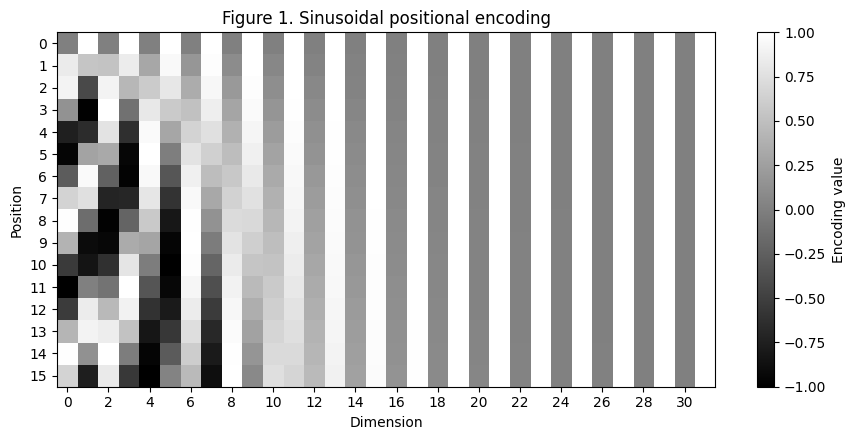

In [2]:
# ============ TODO (Plot 1) ============
# pe = lab07.positional_encoding(lab07.MAX_LEN, lab07.D_MODEL)[0]   # (16, 32)
# Show it with plt.imshow(..., aspect='auto', cmap='gray') plus a colourbar.
# Label the axes (position 0-15 down, dimension 0-31 across) and give it a title.
# =======================================

# 1. 배치용 차원을 제거해 (16, 32) 행렬을 얻는다.
pe = lab07.positional_encoding(
    lab07.MAX_LEN,
    lab07.D_MODEL,
)[0]

# 2. 행은 position, 열은 dimension인 히트맵을 그린다.
fig, ax = plt.subplots(figsize=(9, 4.5))

image = ax.imshow(
    pe.detach().cpu().numpy(),
    aspect="auto",
    cmap="gray",
    vmin=-1.0,
    vmax=1.0,
    origin="upper",
    interpolation="nearest",
)

# 3. 축과 색상 막대를 표시한다.
ax.set_xlabel("Dimension")
ax.set_ylabel("Position")
ax.set_title("Figure 1. Sinusoidal positional encoding")

ax.set_xticks(range(0, lab07.D_MODEL, 2))
ax.set_yticks(range(lab07.MAX_LEN))

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Encoding value")

# 4. 보고서에 사용할 PNG로 저장한다.
fig.tight_layout()
fig.savefig(
    "fig1_positional_encoding.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Plot 2 — Attention weights for one log

The cell below retrains the `encoder_pos` configuration. It uses the same seed as
`run_experiment`, so it is the same model, and then reads the attention weights out of your
`EncoderBlock`. Nothing here is graded; the plot after it is.

In [3]:
lab07.set_seed(lab07.SEED)
model = lab07.SeqClassifier(use_attention=True, use_positional=True)
lab07.train_model(model, data)

i = 0                                        # try a few different logs
tokens, mask = data['x_val'][i:i + 1], data['mask_val'][i:i + 1]
model.eval()
with torch.no_grad():
    h = model.embed(tokens) + model.pe[:, :tokens.shape[1]]
    _, attn = model.encoder(h, mask[:, None, None, :])
attn = attn[0].mean(dim=0)                   # average the 4 heads -> (16, 16)

print('token ids      :', tokens[0].tolist())
print('real events    :', int(mask[0].sum()), 'of', mask.shape[1])
print('heat alarm at  :', (tokens[0] == 1).nonzero().item())
print('pressure at    :', (tokens[0] == 2).nonzero().item())
print('label          :', data['y_val'][i].item(), '(1 = heat first)')

token ids      : [5, 5, 2, 1, 6, 5, 3, 4, 0, 0, 0, 0, 0, 0, 0, 0]
real events    : 8 of 16
heat alarm at  : 3
pressure at    : 2
label          : 0.0 (1 = heat first)


PASS: PAD key 열의 가중치는 모두 정확히 0입니다.
PASS: 각 query 행의 가중치 합은 1입니다.


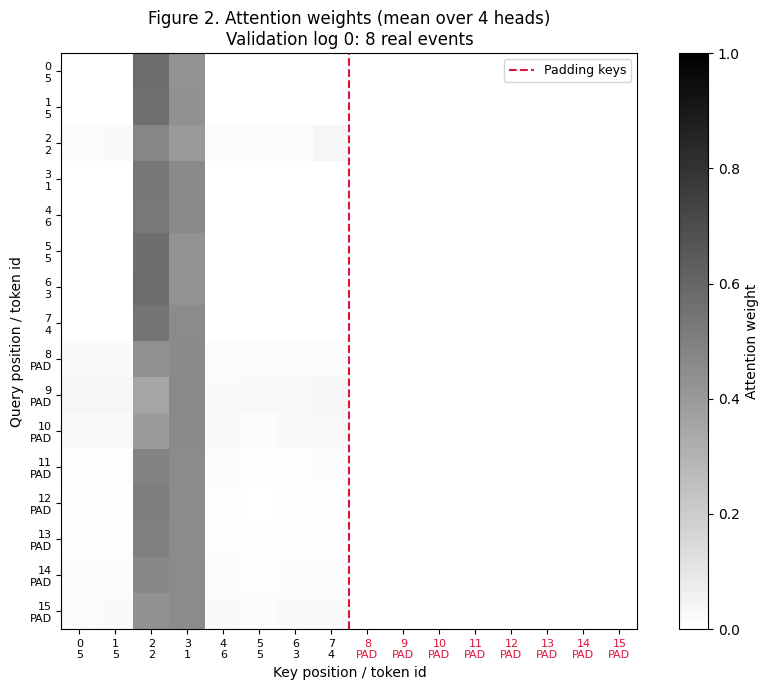

In [4]:
# ============ TODO (Plot 2) ============
# Show `attn` (16 x 16) with plt.imshow(..., cmap='gray_r') plus a colourbar.
# Rows are queries, columns are keys. Label both axes and mark which columns are padding.
# Comment: what weight do the padded columns get, and is that what your mask should do?
# =======================================

# 1. 기존 준비 셀에서 얻은 attention과 mask를 CPU로 옮긴다.
weights = attn.detach().cpu()
is_real = mask[0].detach().cpu()
token_ids = tokens[0].detach().cpu().tolist()

n_positions = weights.shape[0]
n_real = int(is_real.sum().item())

# 2. 각 위치의 번호와 토큰을 축 라벨로 만든다.
# 첫 줄은 위치 번호, 둘째 줄은 token id 또는 PAD이다.
tick_labels = [
    f"{position}\n{token_ids[position]}"
    if bool(is_real[position])
    else f"{position}\nPAD"
    for position in range(n_positions)
]

# 3. query가 행, key가 열인 attention 행렬을 그린다.
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    weights.numpy(),
    cmap="gray_r",
    vmin=0.0,
    vmax=1.0,
    aspect="equal",
    origin="upper",
    interpolation="nearest",
)

ax.set_xticks(range(n_positions))
ax.set_yticks(range(n_positions))
ax.set_xticklabels(tick_labels, fontsize=8)
ax.set_yticklabels(tick_labels, fontsize=8)

ax.set_xlabel("Key position / token id")
ax.set_ylabel("Query position / token id")
ax.set_title(
    "Figure 2. Attention weights "
    f"(mean over {lab07.N_HEADS} heads)\n"
    f"Validation log {i}: {n_real} real events"
)

# 4. PAD key 열을 빨간 라벨과 경계선으로 표시한다.
for tick, keep in zip(
    ax.get_xticklabels(),
    is_real.tolist(),
):
    if not keep:
        tick.set_color("crimson")

if n_real < n_positions:
    ax.axvline(
        n_real - 0.5,
        color="crimson",
        linestyle="--",
        linewidth=1.5,
        label="Padding keys",
    )
    ax.legend(loc="upper right", fontsize=9)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Attention weight")

# 5. 마스크와 softmax의 동작을 직접 확인한다.
assert torch.all(weights[:, ~is_real] == 0), (
    "PAD key 열의 attention이 0이 아닙니다."
)

assert torch.allclose(
    weights.sum(dim=-1),
    torch.ones(n_positions, dtype=weights.dtype),
    atol=1e-5,
), "Attention 행의 합이 1이 아닙니다."

print("PASS: PAD key 열의 가중치는 모두 정확히 0입니다.")
print("PASS: 각 query 행의 가중치 합은 1입니다.")

# 6. 보고서용 PNG로 저장한다.
fig.tight_layout()
fig.savefig(
    "fig2_attention_weights.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Plot 3 — The ablation

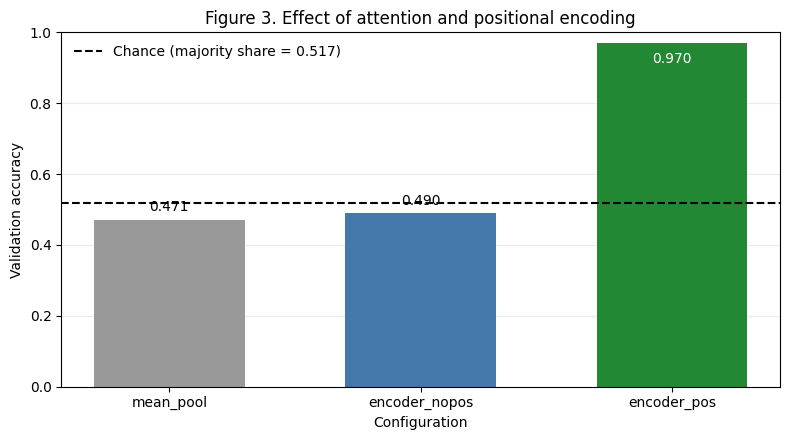

Validation positive rate: 0.517
Majority-class chance level: 0.517


In [5]:
# ============ TODO (Plot 3) ============
# Bar chart of validation accuracy for the three keys of `results`
# ('mean_pool', 'encoder_nopos', 'encoder_pos').
# Draw a horizontal line at the chance level (the majority share of data['y_val'])
# with plt.axhline, and add a legend. Set the y-axis from 0 to 1.
# =======================================

# 1. CONFIGS 순서대로 모델 이름과 정확도를 가져온다.
names = list(lab07.CONFIGS.keys())
accuracies = [
    results[name]["accuracy"]
    for name in names
]

# 2. 검증 데이터의 다수 클래스 비율을 기준선으로 계산한다.
positive_rate = data["y_val"].float().mean().item()
chance = max(positive_rate, 1.0 - positive_rate)

# 3. 정확도 막대그래프를 그린다.
fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    names,
    accuracies,
    color=["#999999", "#4477AA", "#228833"],
    width=0.6,
)

# 4. chance line과 축을 표시한다.
ax.axhline(
    chance,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Chance (majority share = {chance:.3f})",
)

ax.set_ylim(0.0, 1.0)
ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_ylabel("Validation accuracy")
ax.set_xlabel("Configuration")
ax.set_title("Figure 3. Effect of attention and positional encoding")

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left", frameon=False)

# 5. 각 막대에 실제 정확도를 표시한다.
for bar, accuracy in zip(bars, accuracies):
    high = accuracy >= 0.94

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy - 0.025 if high else accuracy + 0.015,
        f"{accuracy:.3f}",
        ha="center",
        va="top" if high else "bottom",
        color="white" if high else "black",
    )

# 6. 보고서용 PNG로 저장한다.
fig.tight_layout()
fig.savefig(
    "fig3_ablation.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"Validation positive rate: {positive_rate:.3f}")
print(f"Majority-class chance level: {chance:.3f}")